# YOLOv8n Training Progress

## What is the purpose?

This experiment checks whether a mobile-friendly AI model can learn to detect obstacles needed by the assistive-navigation app.

**Simple flow:** Images → Training → Validation → Improvement

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

ROOT = next((path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (path / 'notebooks' / '02_training_progress_presenter.ipynb').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from inside the thesis workspace.')
from ultralytics import YOLO
RUN = ROOT / 'runs' / 'yolov8n_pilot'
data_root = ROOT / 'data' / 'processed' / 'rod_pilot_7class'
train_images_dir = data_root / 'images' / 'train'
validation_images_dir = data_root / 'images' / 'val'
train_labels_dir = data_root / 'labels' / 'train'
validation_labels_dir = data_root / 'labels' / 'val'
summary = json.loads((RUN / 'pilot_summary.json').read_text(encoding='utf-8'))
display(Markdown(
    f"## What did we do?\n\n"
    f"- Used **{summary['train_images']:,} images** to train the model\n"
    f"- Used **{summary['validation_images']:,} separate images** to check its performance\n"
    f"- Trained **{len(summary['classes'])} obstacle classes:** person, chair, stairs, car, bicycle, electrical pole, and plant pot\n"
    f"- Completed **{summary['epochs']} training rounds** using the {summary['gpu']}"
))
display(Markdown(
    f"### Where are the files on this laptop?\n\n"
    f"- Training images: `{train_images_dir}` (**{len(list(train_images_dir.glob('*.jpg'))):,} files**)\n"
    f"- Validation images: `{validation_images_dir}` (**{len(list(validation_images_dir.glob('*.jpg'))):,} files**)\n"
    f"- Bounding-box labels: `{data_root / 'labels'}`\n"
    f"- Trained model and results: `{RUN}`\n\n"
    "The images came from the [ROD assistive-obstacle dataset](https://huggingface.co/datasets/Abtinzandi/Obstacle-Detection-Dataset-YOLO). "
    "They were downloaded to the project so the experiment can be inspected locally."
))

## What did we do?

- Used **2,000 images** to train the model
- Used **400 separate images** to check its performance
- Trained **7 obstacle classes:** person, chair, stairs, car, bicycle, electrical pole, and plant pot
- Completed **5 training rounds** using the NVIDIA GeForce RTX 3050 Laptop GPU

### Where are the files on this laptop?

- Training images: `C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\data\processed\rod_pilot_7class\images\train` (**2,000 files**)
- Validation images: `C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\data\processed\rod_pilot_7class\images\val` (**400 files**)
- Bounding-box labels: `C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\data\processed\rod_pilot_7class\labels`
- Trained model and results: `C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\runs\yolov8n_pilot`

The images came from the [ROD assistive-obstacle dataset](https://huggingface.co/datasets/Abtinzandi/Obstacle-Detection-Dataset-YOLO). They were downloaded to the project so the experiment can be inspected locally.

In [2]:
metrics = pd.DataFrame({
    'Result': ['Correctness of detections', 'Obstacles detected', 'Overall detection score', 'Stricter detection score'],
    'Technical metric': ['Precision', 'Recall', 'mAP@0.5', 'mAP@0.5–0.95'],
    'Pilot value': [summary['precision'], summary['recall'], summary['mAP50'], summary['mAP50_95']],
})
metrics['Pilot value'] = metrics['Pilot value'].map(lambda value: f'{value:.1%}')
display(Markdown('## What was the result?'))
display(metrics.style.hide(axis='index'))
display(Markdown(
    f"**Main result:** The preliminary model reached **{summary['mAP50']:.1%} mAP@0.5** after five training rounds. "
    "This shows that the training pipeline works, but it is not yet the final thesis evaluation result."
))
display(Markdown(
    f"### What each metric means\n\n"
    f"- **Precision — {summary['precision']:.1%}:** Of all the objects the model said it detected, around {summary['precision']:.1%} were correct. Higher precision means fewer false detections.\n"
    f"- **Recall — {summary['recall']:.1%}:** Of all the actual obstacles in the validation images, the model detected around {summary['recall']:.1%}. This means it still missed approximately {1-summary['recall']:.1%}.\n"
    f"- **mAP@0.5 — {summary['mAP50']:.1%}:** This is the overall detection score across all seven classes using the basic 50% bounding-box overlap requirement.\n"
    f"- **Stricter mAP — {summary['mAP50_95']:.1%}:** This measures whether the object classification is correct and how accurately the bounding boxes are placed under stricter requirements. It is stricter than mAP@0.5, so a lower score is expected."
))
display(Markdown(
    f"### Is this a good result?\n\n"
    f"It is a **promising preliminary result** for only five training rounds. Precision of **{summary['precision']:.1%}** means most generated detections were correct, "
    f"while recall of **{summary['recall']:.1%}** shows that the model still missed some labeled obstacles. "
    "Therefore, the result is good enough to demonstrate progress, but not good enough to claim that the application is ready or safe for real navigation."
))

## What was the result?

Result,Technical metric,Pilot value
Correctness of detections,Precision,77.5%
Obstacles detected,Recall,62.7%
Overall detection score,mAP@0.5,71.9%
Stricter detection score,mAP@0.5–0.95,50.6%


**Main result:** The preliminary model reached **71.9% mAP@0.5** after five training rounds. This shows that the training pipeline works, but it is not yet the final thesis evaluation result.

### What each metric means

- **Precision — 77.5%:** Of all the objects the model said it detected, around 77.5% were correct. Higher precision means fewer false detections.
- **Recall — 62.7%:** Of all the actual obstacles in the validation images, the model detected around 62.7%. This means it still missed approximately 37.3%.
- **mAP@0.5 — 71.9%:** This is the overall detection score across all seven classes using the basic 50% bounding-box overlap requirement.
- **Stricter mAP — 50.6%:** This measures whether the object classification is correct and how accurately the bounding boxes are placed under stricter requirements. It is stricter than mAP@0.5, so a lower score is expected.

### Is this a good result?

It is a **promising preliminary result** for only five training rounds. Precision of **77.5%** means most generated detections were correct, while recall of **62.7%** shows that the model still missed some labeled obstacles. Therefore, the result is good enough to demonstrate progress, but not good enough to claim that the application is ready or safe for real navigation.

## Important limitation

These metrics evaluate **object detection on the validation dataset only**. They do not yet measure distance estimation, alert prioritization, mobile performance, or real-world navigation safety.

## What can the model detect?

These are individual validation examples. The per-class table below provides the overall performance.

Results saved to C:\Users\User\Documents\first_year_files\THIRD_YEAR\THESIS\runs\yolov8n_pilot\presenter_examples


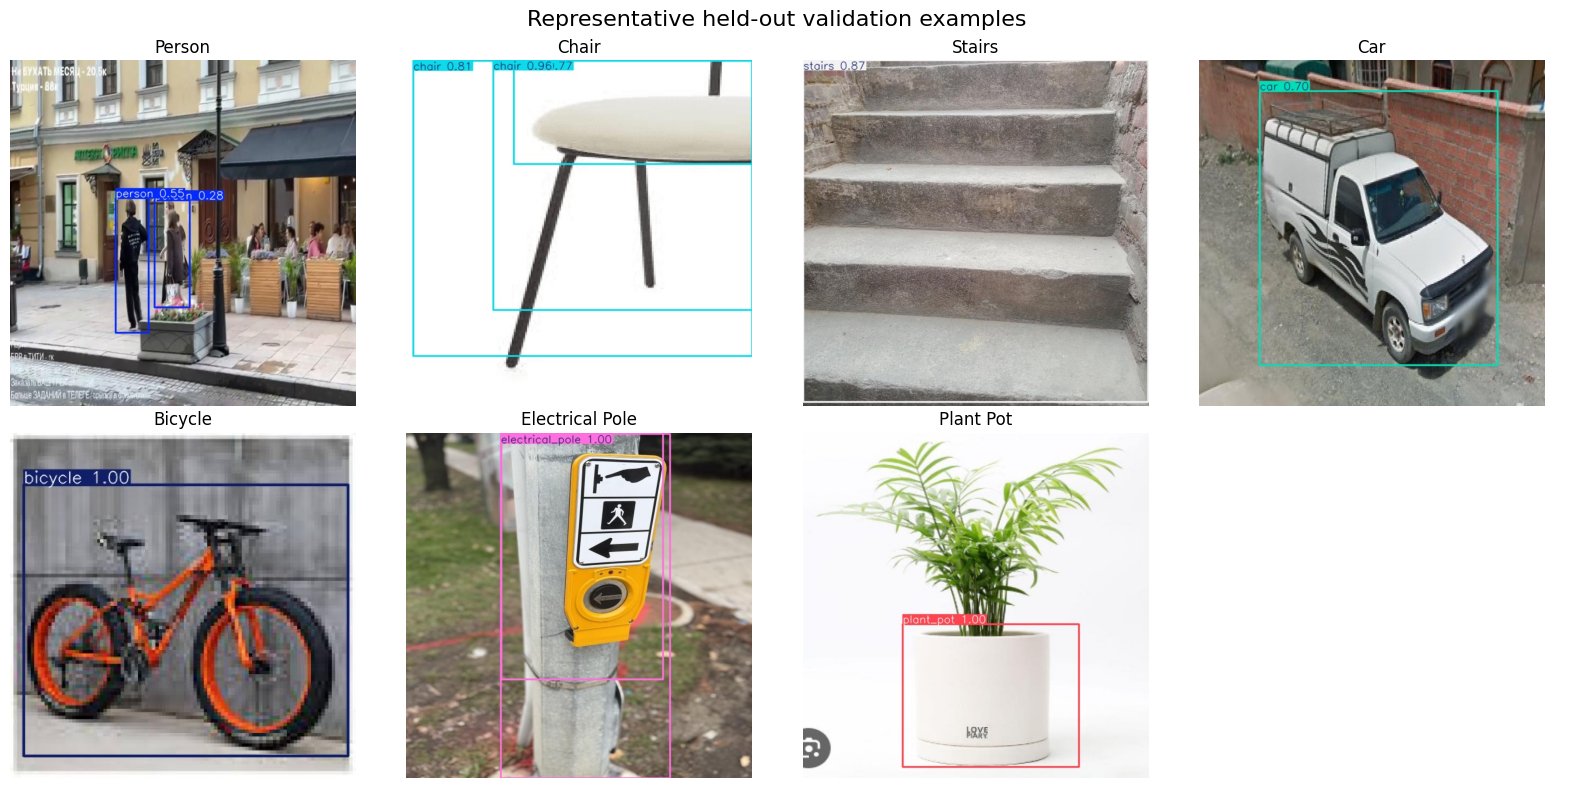

In [3]:
display(Markdown('## What can the model detect?'))
display(Markdown('These are individual validation examples. The per-class table below provides the overall performance.'))
selected = []
used = set()
preferred_examples = {'bicycle': 'IMG_23531'}
for class_id, class_name in enumerate(summary['classes']):
    if class_name in preferred_examples:
        stem = preferred_examples[class_name]
        selected.append((class_name, data_root / 'images' / 'val' / f'{stem}.jpg'))
        used.add(stem)
        continue
    for label_path in sorted((data_root / 'labels' / 'val').glob('*.txt')):
        ids = {int(line.split()[0]) for line in label_path.read_text().splitlines() if line.strip()}
        if class_id in ids and label_path.stem not in used:
            selected.append((class_name, data_root / 'images' / 'val' / f'{label_path.stem}.jpg'))
            used.add(label_path.stem); break
model_path = Path(summary['best_weights'])
if not model_path.is_file():
    model_path = RUN / model_path.parent.parent.name / 'weights' / model_path.name
if not model_path.is_file():
    raise FileNotFoundError(f'Trained model not found: {model_path}')
model = YOLO(str(model_path))
example_dir = RUN / 'presenter_examples'
model.predict([str(path) for _, path in selected], conf=0.25, imgsz=summary['image_size'], device=0, save=True, project=str(RUN), name='presenter_examples', exist_ok=True, verbose=False)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (class_name, source_path) in zip(axes.flat, selected):
    predicted = example_dir / source_path.name
    ax.imshow(PILImage.open(predicted)); ax.set_title(class_name.replace('_', ' ').title()); ax.axis('off')
for ax in axes.flat[len(selected):]: ax.axis('off')
plt.suptitle('Representative held-out validation examples', fontsize=16); plt.tight_layout()
presenter_montage = RUN / 'presenter_prediction_montage.png'
plt.savefig(presenter_montage, dpi=150, bbox_inches='tight'); plt.show()

In [4]:
per_class = pd.read_csv(RUN / 'final_per_class_metrics.csv')
class_table = per_class.copy()
class_table['class'] = class_table['class'].str.replace('_', ' ').str.title()
class_table['mAP@0.5'] = class_table['mAP@0.5'].map(lambda value: f'{value:.1%}')
class_table = class_table[['class', 'mAP@0.5']].rename(columns={'class': 'Obstacle class', 'mAP@0.5': 'Pilot score'})
display(Markdown('## How did each obstacle class perform?'))
display(class_table.style.hide(axis='index'))
best = per_class.loc[per_class['mAP@0.5'].idxmax()]
weakest = per_class.loc[per_class['mAP@0.5'].idxmin()]
display(Markdown(
    f"## What did we learn?\n\n"
    f"- Strongest pilot class: **{best['class'].replace('_', ' ')} ({best['mAP@0.5']:.1%})**\n"
    f"- Class needing the most improvement: **{weakest['class'].replace('_', ' ')} ({weakest['mAP@0.5']:.1%})**\n"
    f"- The training pipeline works, but the model still needs more balanced and campus-specific data."
))

## How did each obstacle class perform?

Obstacle class,Pilot score
Person,68.0%
Chair,92.0%
Stairs,79.0%
Car,82.5%
Bicycle,72.1%
Electrical Pole,18.1%
Plant Pot,91.6%


## What did we learn?

- Strongest pilot class: **chair (92.0%)**
- Class needing the most improvement: **electrical pole (18.1%)**
- The training pipeline works, but the model still needs more balanced and campus-specific data.

## Next step

1. Add campus images, doors, and tables.
2. Add more examples of weak classes such as electrical poles.
3. Conduct longer training and final testing.
4. Convert the best model for use in the Android app.